# Overview

# Data source & scope

# Load data

In [1]:
import os
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, display

NOTEBOOK_DIR = Path.cwd()
DATA_PATH = os.path.join("..", "data", "raw", "complaints.csv")
DATA_PATH_CANDIDATES = [
    NOTEBOOK_DIR / DATA_PATH,
    NOTEBOOK_DIR / "data" / "raw" / "complaints.csv",
    NOTEBOOK_DIR.parent / "data" / "raw" / "complaints.csv",
]
resolved_data_path = next((path for path in DATA_PATH_CANDIDATES if path.exists()), None)

if resolved_data_path is None:
    raise FileNotFoundError(
        "Complaints data file not found. Checked: " + ", ".join(str(path) for path in DATA_PATH_CANDIDATES)
    )

processed_dir = resolved_data_path.parent.parent / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
db_path = processed_dir / "cfpb.duckdb"
con = duckdb.connect(str(db_path))
requested_columns = [
    "Date received",
    "Product",
    "Sub-product",
    "Issue",
    "Sub-issue",
    "Company",
    "State",
    "Company response to consumer",
    "Timely response?",
    "Consumer disputed?",
]
cached_clean_exists = con.execute(
    "SELECT COUNT(*) FROM information_schema.tables WHERE table_name = 'complaints_clean'"
).fetchone()[0] > 0

if cached_clean_exists:
    print(f"Using cached DuckDB tables from {db_path}")
else:
    print(f"Building DuckDB tables for the first time at {db_path}")
    raw_columns = con.execute(
        "SELECT * FROM read_csv_auto(?, header=True, all_varchar=True, parallel=false) LIMIT 0",
        [str(resolved_data_path)],
    ).df().columns.tolist()
    column_name_map = {col.strip(): col for col in raw_columns}
    selected_columns = [col for col in requested_columns if col in column_name_map]

    if not selected_columns:
        raise ValueError("None of the required analysis columns were found in the complaints export.")

    select_list = ", ".join(
        [
            f'"{column_name_map[col]}" AS "{col}"' if column_name_map[col] != col else f'"{col}"'
            for col in selected_columns
        ]
    )
    clean_select_parts = []
    for col in selected_columns:
        if col in ["Company", "Product", "Issue", "Sub-issue"]:
            clean_select_parts.append(f'NULLIF(TRIM("{col}"), \'\') AS "{col}"')
        elif col == "State":
            clean_select_parts.append('NULLIF(TRIM("State"), \'\') AS "State"')
        else:
            clean_select_parts.append(f'"{col}"')
    clean_select_parts.extend([
        'TRY_CAST("Date received" AS DATE) AS parsed_date',
        'strftime(TRY_CAST("Date received" AS DATE), \'%Y-%m\') AS year_month',
    ])
    clean_select_sql = ", ".join(clean_select_parts)

    con.execute("DROP TABLE IF EXISTS complaints_raw")
    con.execute(
        "CREATE TABLE complaints_raw AS SELECT * FROM read_csv_auto(?, header=True, all_varchar=True, parallel=false)",
        [str(resolved_data_path)],
    )
    con.execute("DROP TABLE IF EXISTS complaints_clean")
    con.execute(
        f"CREATE TABLE complaints_clean AS SELECT {clean_select_sql} FROM (SELECT {select_list} FROM complaints_raw)"
    )

clean_columns = con.execute("PRAGMA table_info('complaints_clean')").df()["name"].tolist()
df_columns = [col for col in requested_columns if col in clean_columns]
row_count = con.execute("SELECT COUNT(*) FROM complaints_clean").fetchone()[0]
preview_select = ", ".join([f'\"{col}\"' for col in df_columns])
df_preview = con.execute(f"SELECT {preview_select} FROM complaints_clean LIMIT 5").df()

print("Using data file:", resolved_data_path)
print("DataFrame shape:", (row_count, len(df_columns)))
print("First 20 columns:", df_columns[:20])
display(df_preview)


Using cached DuckDB tables from /Users/ahannair/Desktop/OnlineRetailRevenueLeakage-CFPB/notebooks/../data/processed/cfpb.duckdb
Using data file: /Users/ahannair/Desktop/OnlineRetailRevenueLeakage-CFPB/notebooks/../data/raw/complaints.csv
DataFrame shape: (13717777, 10)
First 20 columns: ['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company', 'State', 'Company response to consumer', 'Timely response?', 'Consumer disputed?']


,Date received,Product,Sub-product,Issue,Sub-issue,Company,State,Company response to consumer,Timely response?,Consumer disputed?
0,2020-07-13,Mortgage,FHA mortgage,Trouble during payment process,None,"SAMC Honebee TRS, LLC",AL,Closed with explanation,Yes,N/A
1,2023-12-16,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Information belongs to someone else,"FactorTrust, Inc.",NY,Closed with explanation,Yes,N/A
2,2024-01-27,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account information incorrect,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",NY,Closed with non-monetary relief,Yes,N/A
3,2019-05-22,"Credit reporting, credit repair services, or o...",Credit reporting,Problem with fraud alerts or security freezes,None,Experian Information Solutions Inc.,CA,Closed with explanation,Yes,N/A
4,2024-12-13,Credit reporting or other personal consumer re...,Credit reporting,Problem with a company's investigation into an...,Investigation took more than 30 days,"EQUIFAX, INC.",MO,Closed with non-monetary relief,Yes,N/A


# Data dictionary (columns used)

In [2]:
data_dictionary_rows = [
    {"field": "Date received", "used_for": "Monthly trend analysis and time-based filtering", "notes": "Complaint intake date used to derive year_month"},
    {"field": "Product", "used_for": "Primary product segmentation", "notes": "High-level product category"},
    {"field": "Sub-product", "used_for": "More granular product driver analysis", "notes": "Product subtype when available"},
    {"field": "Issue", "used_for": "Root-cause and complaint theme analysis", "notes": "Primary consumer issue"},
    {"field": "Sub-issue", "used_for": "Detailed issue driver analysis", "notes": "Secondary issue detail when available"},
    {"field": "Company", "used_for": "Company-level scorecards and benchmarking", "notes": "Named company associated with the complaint"},
    {"field": "State", "used_for": "Geographic segmentation", "notes": "Consumer state abbreviation when reported"},
    {"field": "Company response to consumer", "used_for": "Response outcome and operational analysis", "notes": "Reported response category"},
    {"field": "Timely response?", "used_for": "Operational performance KPI", "notes": "Binary timeliness indicator"},
    {"field": "Consumer disputed?", "used_for": "Potential dissatisfaction and escalation signal", "notes": "Legacy dispute indicator when included in export"},
]

for row in data_dictionary_rows:
    if row["field"] not in df_columns:
        row["notes"] = "not present in this export"

data_dictionary = pd.DataFrame(data_dictionary_rows, columns=["field", "used_for", "notes"])
display(data_dictionary)


,field,used_for,notes
0,Date received,Monthly trend analysis and time-based filtering,Complaint intake date used to derive year_month
1,Product,Primary product segmentation,High-level product category
2,Sub-product,More granular product driver analysis,Product subtype when available
3,Issue,Root-cause and complaint theme analysis,Primary consumer issue
4,Sub-issue,Detailed issue driver analysis,Secondary issue detail when available
5,Company,Company-level scorecards and benchmarking,Named company associated with the complaint
6,State,Geographic segmentation,Consumer state abbreviation when reported
7,Company response to consumer,Response outcome and operational analysis,Reported response category
8,Timely response?,Operational performance KPI,Binary timeliness indicator
9,Consumer disputed?,Potential dissatisfaction and escalation signal,Legacy dispute indicator when included in export


# Cleaning & validation

In [3]:
DATE_COL = "Date received"

if DATE_COL not in df_columns:
    raise KeyError(
        f"Required date column '{DATE_COL}' was not found in the dataset. Available columns include: {df_columns[:20]}"
    )

date_summary = con.execute(
    """
    SELECT
        MIN(parsed_date) AS min_date,
        MAX(parsed_date) AS max_date,
        COUNT(DISTINCT year_month) AS unique_months
    FROM complaints_clean
    WHERE parsed_date IS NOT NULL
    """
).df().iloc[0]
print("Date range:", date_summary["min_date"], "to", date_summary["max_date"])
print("Number of unique months:", int(date_summary["unique_months"]))


Date range: 2011-12-01 00:00:00 to 2026-02-17 00:00:00
Number of unique months: 171


In [4]:
key_fields = [
    "Date received",
    "Product",
    "Sub-product",
    "Issue",
    "Sub-issue",
    "Company",
    "State",
    "Company response to consumer",
    "Timely response?",
    "Consumer disputed?",
]

present_key_fields = [field for field in key_fields if field in df_columns]
if present_key_fields:
    missingness_query = "SELECT " + ", ".join(
        [
            f"ROUND(100.0 * AVG(CASE WHEN \"{field}\" IS NULL OR TRIM(CAST(\"{field}\" AS VARCHAR)) = '' THEN 1 ELSE 0 END), 2) AS \"{field}\""
            for field in present_key_fields
        ]
    ) + " FROM complaints_clean"
    missingness_pct = con.execute(missingness_query).df().iloc[0].sort_values(ascending=False)
else:
    missingness_pct = pd.Series(dtype=float)
print("Missingness percentage for key fields present:")
print(missingness_pct)

con.execute("DROP TABLE IF EXISTS complaints_us")
if "State" in df_columns:
    con.execute('CREATE TEMP TABLE complaints_us AS SELECT * FROM complaints_clean WHERE parsed_date IS NOT NULL AND "State" IS NOT NULL')
else:
    con.execute('CREATE TEMP TABLE complaints_us AS SELECT * FROM complaints_clean WHERE parsed_date IS NOT NULL')

df_us_count = con.execute('SELECT COUNT(*) FROM complaints_us').fetchone()[0]
unique_month_count = con.execute('SELECT COUNT(DISTINCT year_month) FROM complaints_us').fetchone()[0]

if "Product" in df_columns:
    print("Top 10 Product values:")
    print(con.execute('SELECT "Product", COUNT(*) AS complaint_count FROM complaints_us GROUP BY 1 ORDER BY 2 DESC LIMIT 10').df().set_index("Product")["complaint_count"])
else:
    print("Top 10 Product values: column not present")

if "Issue" in df_columns:
    print("Top 10 Issue values:")
    print(con.execute('SELECT "Issue", COUNT(*) AS complaint_count FROM complaints_us GROUP BY 1 ORDER BY 2 DESC LIMIT 10').df().set_index("Issue")["complaint_count"])
else:
    print("Top 10 Issue values: column not present")

assert df_us_count > 0, "df_us is empty after filtering for rows with non-null State values."
assert unique_month_count > 6, "Expected more than 6 unique months in df_us for trend analysis."


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Missingness percentage for key fields present:
Sub-issue                       6.47
Sub-product                     1.72
State                           0.43
Date received                   0.00
Product                         0.00
Issue                           0.00
Company                         0.00
Company response to consumer    0.00
Timely response?                0.00
Consumer disputed?              0.00
Name: 0, dtype: float64


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Top 10 Product values:
Product
Credit reporting or other personal consumer reports                             8524970
Credit reporting, credit repair services, or other personal consumer reports    2154507
Debt collection                                                                 1001836
Mortgage                                                                         434499
Checking or savings account                                                      335365
Credit card                                                                      287106
Credit card or prepaid card                                                      201676
Money transfer, virtual currency, or money service                               159839
Credit reporting                                                                 139956
Student loan                                                                     120105
Name: complaint_count, dtype: int64
Top 10 Issue values:
Issue
Incorrect information on y

# KPI definitions

# Time-series trends

,year_month,complaint_count,timely_response_rate,year_month_dt
0,2011-12,2521,0.900833,2011-12-01
1,2012-01,3221,0.940391,2012-01-01
2,2012-02,3503,0.961462,2012-02-01
3,2012-03,6207,0.963751,2012-03-01
4,2012-04,5656,0.958628,2012-04-01
...,...,...,...,...
166,2025-10,559388,0.996991,2025-10-01
167,2025-11,540482,0.996168,2025-11-01
168,2025-12,577915,0.996243,2025-12-01
169,2026-01,615090,0.997160,2026-01-01


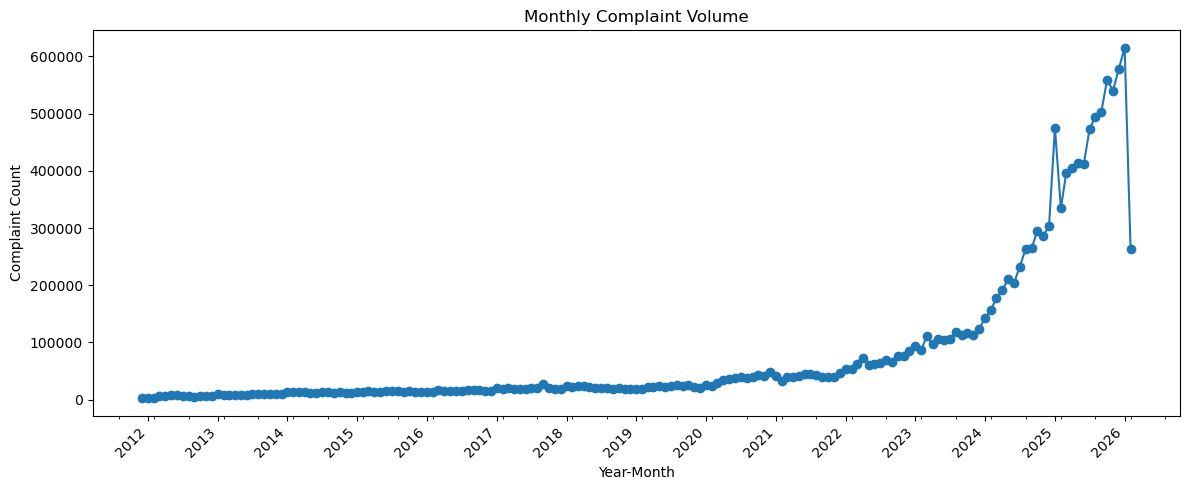

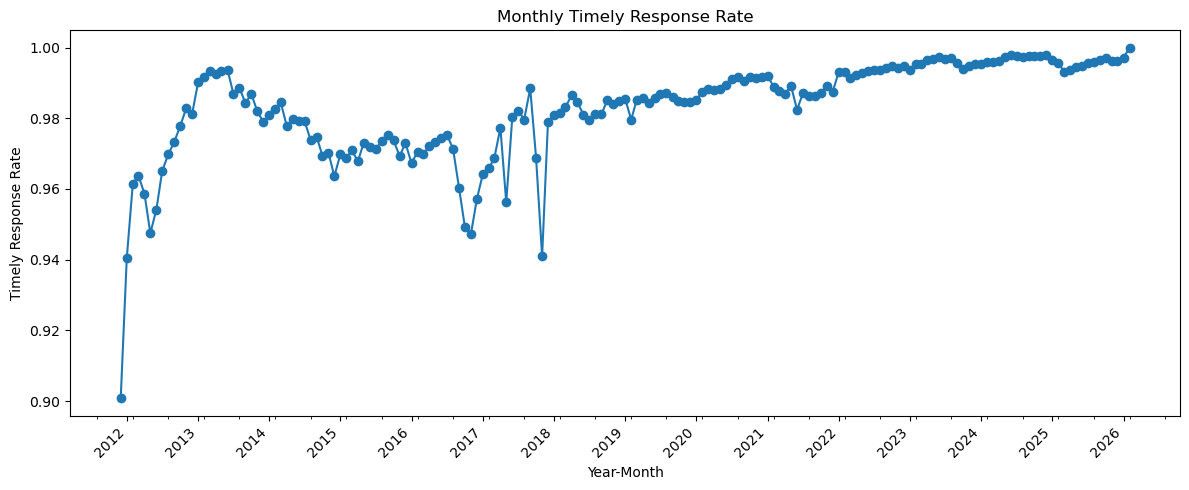

In [5]:
monthly_query = """
SELECT
    year_month,
    COUNT(*) AS complaint_count
{timely_select}
FROM complaints_us
GROUP BY 1
ORDER BY 1
"""

timely_select = ""
if "Timely response?" in df_columns:
    timely_select = ", AVG(CASE WHEN \"Timely response?\" = 'Yes' THEN 1.0 WHEN \"Timely response?\" = 'No' THEN 0.0 ELSE NULL END) AS timely_response_rate"

monthly_table = con.execute(monthly_query.format(timely_select=timely_select)).df()
monthly_table["year_month_dt"] = pd.to_datetime(monthly_table["year_month"], format="%Y-%m")

# Optional: drop the latest month if it is incomplete and creates an artificial dip.
# latest_complete_cutoff = pd.Timestamp.today().to_period("M").to_timestamp()
# monthly_table = monthly_table[monthly_table["year_month_dt"] < latest_complete_cutoff].copy()

display(monthly_table)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_table["year_month_dt"], monthly_table["complaint_count"], marker="o")
ax.set_title("Monthly Complaint Volume")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Complaint Count")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator(interval=6))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

if "timely_response_rate" in monthly_table.columns:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(monthly_table["year_month_dt"], monthly_table["timely_response_rate"], marker="o")
    ax.set_title("Monthly Timely Response Rate")
    ax.set_xlabel("Year-Month")
    ax.set_ylabel("Timely Response Rate")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(interval=6))
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# Issue & product drivers

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

risk_theme,Billing/Dispute,Other,Refund/Return,Unauthorized/Fraud
year_month,,,,
2011-12,737.0,1565.0,75.0,144.0
2012-01,953.0,2095.0,84.0,89.0
2012-02,1020.0,2325.0,60.0,98.0
2012-03,1393.0,4625.0,91.0,98.0
2012-04,1257.0,4239.0,67.0,93.0
...,...,...,...,...
2025-10,13698.0,539046.0,0.0,6644.0
2025-11,13142.0,520962.0,0.0,6378.0
2025-12,14611.0,555581.0,0.0,7723.0


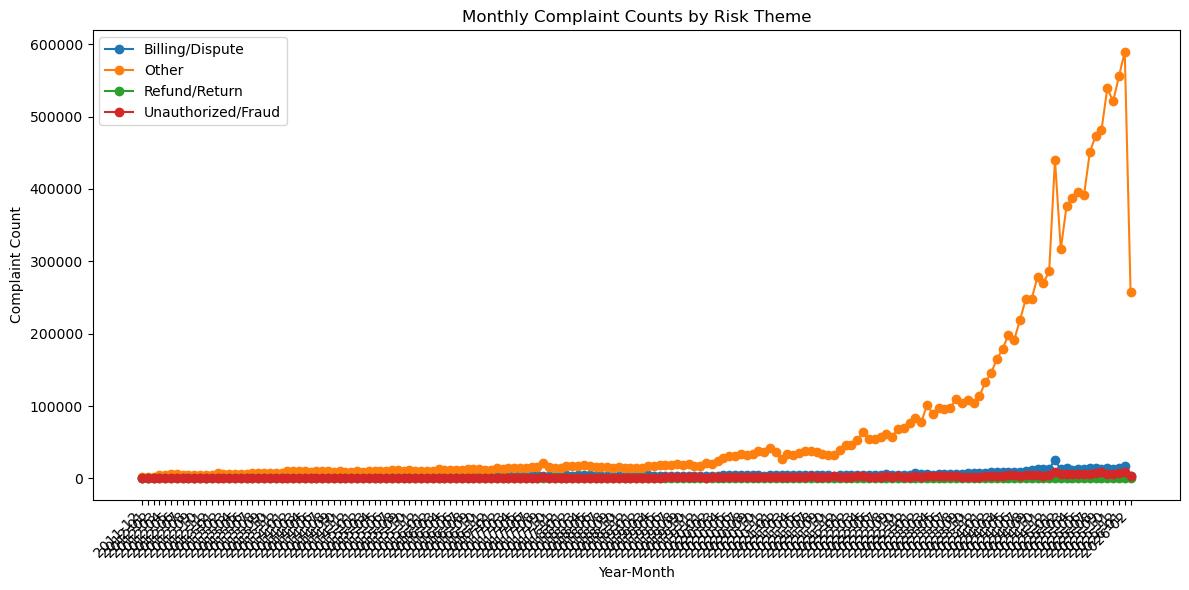

In [6]:
issue_expr = "COALESCE(LOWER(\"Issue\"), '')" if "Issue" in df_columns else "''"
sub_issue_expr = "COALESCE(LOWER(\"Sub-issue\"), '')" if "Sub-issue" in df_columns else "''"
risk_theme_sql = f"""
CREATE TEMP TABLE complaints_scored AS
SELECT
    *,
    CASE
        WHEN regexp_matches(({issue_expr} || ' ' || {sub_issue_expr}), 'unauthori|fraud|scam|identity theft|stolen|counterfeit') THEN 'Unauthorized/Fraud'
        WHEN regexp_matches(({issue_expr} || ' ' || {sub_issue_expr}), 'billing|dispute|charged|charge|fee|payment|statement|balance') THEN 'Billing/Dispute'
        WHEN regexp_matches(({issue_expr} || ' ' || {sub_issue_expr}), 'refund|return|reversal|credit not processed|merchant dispute|cancel') THEN 'Refund/Return'
        ELSE 'Other'
    END AS risk_theme
FROM complaints_us
"""

con.execute("DROP TABLE IF EXISTS complaints_scored")
con.execute(risk_theme_sql)

monthly_risk_theme = con.execute(
    """
    SELECT year_month, risk_theme, COUNT(*) AS complaint_count
    FROM complaints_scored
    GROUP BY 1, 2
    ORDER BY 1, 2
    """
).df().pivot(index="year_month", columns="risk_theme", values="complaint_count").fillna(0)
monthly_risk_theme = monthly_risk_theme.sort_index()

display(monthly_risk_theme)

plt.figure(figsize=(12, 6))
for theme in monthly_risk_theme.columns:
    plt.plot(monthly_risk_theme.index, monthly_risk_theme[theme], marker="o", label=theme)
plt.title("Monthly Complaint Counts by Risk Theme")
plt.xlabel("Year-Month")
plt.ylabel("Complaint Count")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


Top 15 Issues overall:
Issue
Incorrect information on your report                                                5821499
Improper use of your report                                                         2647403
Problem with a company's investigation into an existing problem                     1589382
Problem with a credit reporting company's investigation into an existing problem     587221
Attempts to collect debt not owed                                                    392540
Written notification about debt                                                      202435
Managing an account                                                                  195401
Loan modification,collection,foreclosure                                             111484
Took or threatened to take negative or legal action                                  103113
False statements or representation                                                   102434
Incorrect information on credit report             

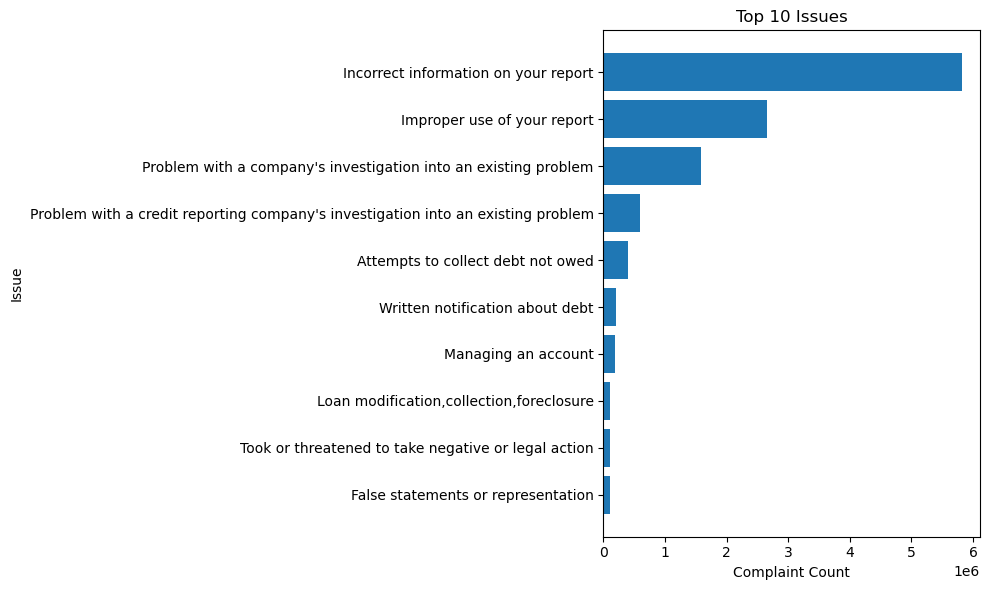

In [7]:
top_15_issues = (
    con.execute(
        'SELECT "Issue", COUNT(*) AS complaint_count FROM complaints_scored GROUP BY 1 ORDER BY 2 DESC LIMIT 15'
    ).df().set_index("Issue")["complaint_count"]
    if "Issue" in df_columns
    else pd.Series(dtype=int)
)
top_10_products = (
    con.execute(
        'SELECT "Product", COUNT(*) AS complaint_count FROM complaints_scored GROUP BY 1 ORDER BY 2 DESC LIMIT 10'
    ).df().set_index("Product")["complaint_count"]
    if "Product" in df_columns
    else pd.Series(dtype=int)
)

print("Top 15 Issues overall:")
print(top_15_issues)

print("\nTop 10 Products overall:")
print(top_10_products)

if "Issue" in df_columns:
    top_issues_within_theme = con.execute(
        """
        WITH ranked AS (
            SELECT
                risk_theme,
                "Issue",
                COUNT(*) AS complaint_count,
                ROW_NUMBER() OVER (PARTITION BY risk_theme ORDER BY COUNT(*) DESC, "Issue") AS rn
            FROM complaints_scored
            GROUP BY 1, 2
        )
        SELECT risk_theme, "Issue", complaint_count
        FROM ranked
        WHERE rn <= 5
        ORDER BY risk_theme, complaint_count DESC, "Issue"
        """
    ).df().set_index(["risk_theme", "Issue"])["complaint_count"]
else:
    top_issues_within_theme = pd.Series(dtype=int)

print("\nTop 5 Issues within each risk_theme:")
print(top_issues_within_theme)

if not top_15_issues.empty:
    chart_data = top_15_issues.head(10).sort_values(ascending=True)
    plt.figure(figsize=(10, 6))
    plt.barh(chart_data.index.astype(str), chart_data.values)
    plt.title("Top 10 Issues")
    plt.xlabel("Complaint Count")
    plt.ylabel("Issue")
    plt.tight_layout()
    plt.show()


# Company-level scorecard

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Company,complaint_count,share_of_total,timely_response_rate,dispute_rate,most_common_issue
0,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",3560013,0.260646,0.999910,0.140728,Incorrect information on your report
1,"EQUIFAX, INC.",3542335,0.259352,0.999499,0.208456,Incorrect information on your report
2,Experian Information Solutions Inc.,3220380,0.235780,0.999974,0.116867,Incorrect information on your report
3,"BANK OF AMERICA, NATIONAL ASSOCIATION",169082,0.012379,0.974710,0.218098,"Loan modification,collection,foreclosure"
4,WELLS FARGO & COMPANY,158651,0.011616,0.976716,0.218104,Managing an account
5,JPMORGAN CHASE & CO.,157000,0.011495,0.999408,0.223777,Managing an account
6,CAPITAL ONE FINANCIAL CORPORATION,150244,0.011000,0.999421,0.179873,Incorrect information on your report
7,"CITIBANK, N.A.",125197,0.009166,0.997093,0.192889,Problem with a purchase shown on your statement
8,SYNCHRONY FINANCIAL,73278,0.005365,0.999181,0.151168,Incorrect information on your report
9,"Block, Inc.",61269,0.004486,0.985033,NaN,Other transaction problem


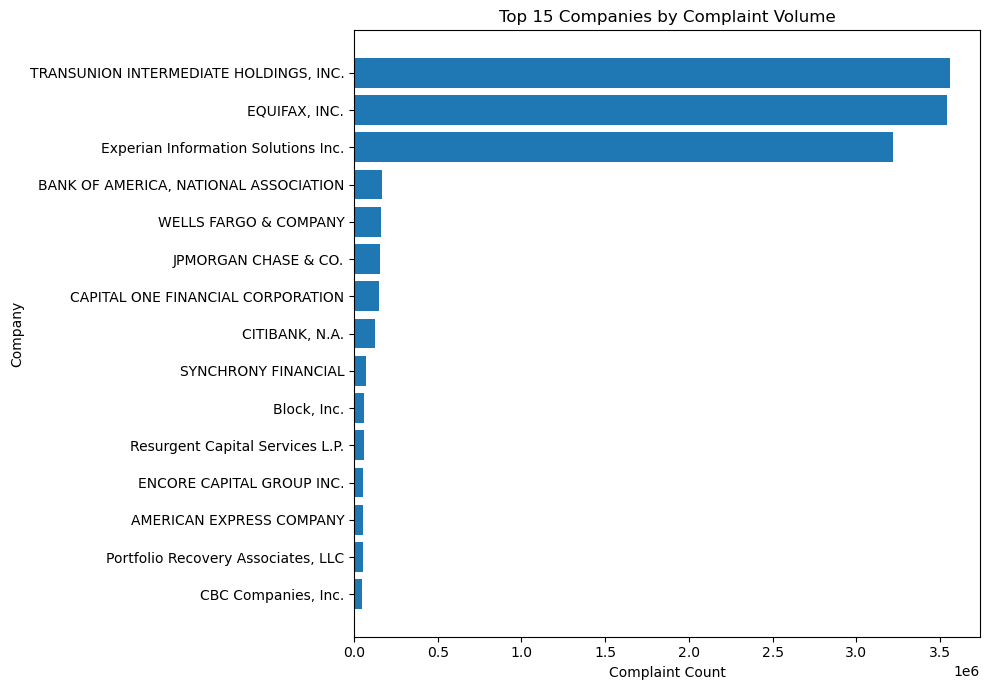

In [8]:
if "Company" not in df_columns:
    raise KeyError("Required column 'Company' was not found in the dataset for company scorecard analysis.")

total_complaints = con.execute('SELECT COUNT(*) FROM complaints_scored').fetchone()[0]
timely_select = ""
if "Timely response?" in df_columns:
    timely_select = ", AVG(CASE WHEN \"Timely response?\" = 'Yes' THEN 1.0 WHEN \"Timely response?\" = 'No' THEN 0.0 ELSE NULL END) AS timely_response_rate"

dispute_select = ""
if "Consumer disputed?" in df_columns:
    dispute_select = ", AVG(CASE WHEN \"Consumer disputed?\" = 'Yes' THEN 1.0 WHEN \"Consumer disputed?\" = 'No' THEN 0.0 ELSE NULL END) AS dispute_rate"

issue_projection = ", NULL AS most_common_issue"
issue_join = ""
issue_group_by = ""
if "Issue" in df_columns:
    issue_projection = ", m.most_common_issue"
    issue_group_by = ", m.most_common_issue"
    issue_join = """
    LEFT JOIN (
        SELECT company, issue AS most_common_issue
        FROM (
            SELECT
                "Company" AS company,
                "Issue" AS issue,
                COUNT(*) AS complaint_count,
                ROW_NUMBER() OVER (PARTITION BY "Company" ORDER BY COUNT(*) DESC, "Issue") AS rn
            FROM complaints_scored
            WHERE "Company" IS NOT NULL
            GROUP BY 1, 2
        ) ranked_issues
        WHERE rn = 1
    ) m ON c."Company" = m.company
    """

company_query = f"""
WITH top_companies AS (
    SELECT "Company"
    FROM complaints_scored
    WHERE "Company" IS NOT NULL
    GROUP BY 1
    ORDER BY COUNT(*) DESC
    LIMIT 25
)
SELECT
    c."Company" AS Company,
    COUNT(*) AS complaint_count,
    COUNT(*) * 1.0 / {total_complaints} AS share_of_total
    {timely_select}
    {dispute_select}
    {issue_projection}
FROM complaints_scored c
INNER JOIN top_companies t ON c."Company" = t."Company"
{issue_join}
GROUP BY c."Company"{issue_group_by}
ORDER BY complaint_count DESC, Company
"""

company_scorecard = con.execute(company_query).df()
display(company_scorecard)

top_15_company_chart = company_scorecard.head(15).sort_values("complaint_count", ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(top_15_company_chart["Company"], top_15_company_chart["complaint_count"])
plt.title("Top 15 Companies by Complaint Volume")
plt.xlabel("Complaint Count")
plt.ylabel("Company")
plt.tight_layout()
plt.show()


# Operational performance

# Interpretable risk score (prioritization)

In [9]:
risk_scorecard = company_scorecard.copy()

# Weighting logic for prioritization only:
# - 0.60 on complaint volume z-score because sustained complaint volume is the primary signal.
# - 0.25 penalty on low timely response rate, defined as (1 - timely_response_rate), when available.
# - 0.15 penalty on dispute rate, using the observed dispute_rate directly, when available.
complaint_std = risk_scorecard["complaint_count"].std(ddof=0)
if complaint_std == 0 or pd.isna(complaint_std):
    risk_scorecard["complaint_count_zscore"] = 0.0
else:
    risk_scorecard["complaint_count_zscore"] = (
        risk_scorecard["complaint_count"] - risk_scorecard["complaint_count"].mean()
    ) / complaint_std

risk_scorecard["low_timely_penalty"] = 0.0
if "timely_response_rate" in risk_scorecard.columns:
    risk_scorecard["low_timely_penalty"] = 1 - risk_scorecard["timely_response_rate"].fillna(1.0)

risk_scorecard["high_dispute_penalty"] = 0.0
if "dispute_rate" in risk_scorecard.columns:
    risk_scorecard["high_dispute_penalty"] = risk_scorecard["dispute_rate"].fillna(0.0)

risk_scorecard["risk_score"] = (
    0.60 * risk_scorecard["complaint_count_zscore"]
    + 0.25 * risk_scorecard["low_timely_penalty"]
    + 0.15 * risk_scorecard["high_dispute_penalty"]
)

top_15_risk_companies = risk_scorecard.sort_values("risk_score", ascending=False).head(15)
display(
    top_15_risk_companies[
        [
            "Company",
            "risk_score",
            "complaint_count",
            "complaint_count_zscore",
            "low_timely_penalty",
            "high_dispute_penalty",
        ]
    ]
)

print(
    "Interpretation: higher risk_score values indicate companies that combine above-average complaint volume "
    "with weaker service outcomes. The score is for prioritization only, not causal inference or regulatory judgment."
)


,Company,risk_score,complaint_count,complaint_count_zscore,low_timely_penalty,high_dispute_penalty
1,"EQUIFAX, INC.",1.708444,3542335,2.795085,0.000501,0.208456
0,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",1.707848,3560013,2.811194,0.000090,0.140728
2,Experian Information Solutions Inc.,1.518556,3220380,2.501700,0.000026,0.116867
3,"BANK OF AMERICA, NATIONAL ASSOCIATION",-0.128262,169082,-0.278831,0.025290,0.218098
4,WELLS FARGO & COMPANY,-0.134465,158651,-0.288337,0.023284,0.218104
5,JPMORGAN CHASE & CO.,-0.140190,157000,-0.289841,0.000592,0.223777
6,CAPITAL ONE FINANCIAL CORPORATION,-0.150473,150244,-0.295997,0.000579,0.179873
7,"CITIBANK, N.A.",-0.161633,125197,-0.318822,0.002907,0.192889
24,"Early Warning Services, LLC",-0.178740,33195,-0.402660,0.000362,0.418440
12,AMERICAN EXPRESS COMPANY,-0.189988,52227,-0.385317,0.001053,0.272926


Interpretation: higher risk_score values indicate companies that combine above-average complaint volume with weaker service outcomes. The score is for prioritization only, not causal inference or regulatory judgment.


# Executive summary & recommendations

In [10]:
peak_month = monthly_table.loc[monthly_table["complaint_count"].idxmax()]
avg_monthly_complaints = monthly_table["complaint_count"].mean()
top_risk_theme = monthly_risk_theme.sum().sort_values(ascending=False).index[0]
top_risk_theme_count = int(monthly_risk_theme.sum().sort_values(ascending=False).iloc[0])
top_company = company_scorecard.iloc[0]
highest_risk_company = risk_scorecard.sort_values("risk_score", ascending=False).iloc[0]

findings = [
    f"Complaint demand is persistent across {unique_month_count} reporting months, averaging {avg_monthly_complaints:,.0f} complaints per month and peaking in {peak_month['year_month']} at {int(peak_month['complaint_count']):,} complaints.",
    f"{top_risk_theme} is the largest modeled risk theme in the portfolio, accounting for {top_risk_theme_count:,} complaints in the filtered U.S. dataset and indicating where revenue leakage controls are most exposed.",
    f"{top_company['Company']} has the highest complaint volume among the top-25 company cohort with {int(top_company['complaint_count']):,} complaints, representing {top_company['share_of_total']:.1%} of total filtered complaints.",
    f"{highest_risk_company['Company']} ranks highest on the prioritization score at {highest_risk_company['risk_score']:.2f}, reflecting a combined signal from complaint concentration and service-outcome penalties rather than a single metric spike.",
]

if "timely_response_rate" in monthly_table.columns and monthly_table["timely_response_rate"].notna().any():
    latest_timely_rate = monthly_table["timely_response_rate"].dropna().iloc[-1]
    findings.append(
        f"The latest observed monthly timely response rate is {latest_timely_rate:.1%}, making response discipline a material operational lever where companies fall short."
    )

recommendations = [
    f"Prioritize supervisory review and remediation planning for {highest_risk_company['Company']} and the other highest-risk companies, using the score as a triage tool for queue sequencing rather than as a standalone performance verdict.",
    f"Concentrate root-cause reviews on {top_risk_theme} complaints first, because that theme currently contributes the largest complaint burden and is the most likely source of repeatable leakage patterns.",
    "Set monthly operating thresholds for complaint volume and response timeliness, then trigger escalation when a company materially exceeds its recent baseline or misses response expectations.",
]

if "most_common_issue" in company_scorecard.columns and company_scorecard["most_common_issue"].notna().any():
    recommendations.append(
        "Use each company’s most common issue as the starting point for targeted corrective actions so remediation efforts align with the dominant consumer pain point rather than generic controls."
    )

limitations = [
    "This analysis reflects complaint records rather than audited revenue outcomes, so it should be treated as an early-warning indicator and not as direct proof of consumer harm or financial loss.",
    "The risk-theme mapping is rules-based and intentionally simple, which improves interpretability but may under-classify nuanced complaint narratives or misclassify edge cases.",
    "Some operational fields may be missing from a given export, which can reduce the precision of timely-response and dispute-based comparisons across companies.",
]

brief = "\n".join(
    [
        "## Executive brief",
        "",
        "### Findings",
        *[f"- {item}" for item in findings[:5]],
        "",
        "### Recommendations",
        *[f"- {item}" for item in recommendations[:4]],
        "",
        "### Limitations",
        *[f"- {item}" for item in limitations[:3]],
    ]
)

display(Markdown(brief))


## Executive brief

### Findings
- Complaint demand is persistent across 171 reporting months, averaging 79,874 complaints per month and peaking in 2026-01 at 615,090 complaints.
- Other is the largest modeled risk theme in the portfolio, accounting for 12,513,197 complaints in the filtered U.S. dataset and indicating where revenue leakage controls are most exposed.
- TRANSUNION INTERMEDIATE HOLDINGS, INC. has the highest complaint volume among the top-25 company cohort with 3,560,013 complaints, representing 26.1% of total filtered complaints.
- EQUIFAX, INC. ranks highest on the prioritization score at 1.71, reflecting a combined signal from complaint concentration and service-outcome penalties rather than a single metric spike.
- The latest observed monthly timely response rate is 100.0%, making response discipline a material operational lever where companies fall short.

### Recommendations
- Prioritize supervisory review and remediation planning for EQUIFAX, INC. and the other highest-risk companies, using the score as a triage tool for queue sequencing rather than as a standalone performance verdict.
- Concentrate root-cause reviews on Other complaints first, because that theme currently contributes the largest complaint burden and is the most likely source of repeatable leakage patterns.
- Set monthly operating thresholds for complaint volume and response timeliness, then trigger escalation when a company materially exceeds its recent baseline or misses response expectations.
- Use each company’s most common issue as the starting point for targeted corrective actions so remediation efforts align with the dominant consumer pain point rather than generic controls.

### Limitations
- This analysis reflects complaint records rather than audited revenue outcomes, so it should be treated as an early-warning indicator and not as direct proof of consumer harm or financial loss.
- The risk-theme mapping is rules-based and intentionally simple, which improves interpretability but may under-classify nuanced complaint narratives or misclassify edge cases.
- Some operational fields may be missing from a given export, which can reduce the precision of timely-response and dispute-based comparisons across companies.

# Limitations